# BÀI TẬP CUỐI KHOÁ: MACHINE LEARNING
## ĐỀ TÀI: DỰ ĐOÁN HỎNG HÓC THIẾT BỊ DƯỚI DISTRIBUTION SHIFT (PREDICTIVE MAINTENANCE)

---
- **Học viên:** Trần Tiến Cường
- **Mã số sinh viên (MSSV):** `<MSSV>`
- **Khoá học:** Machine Learning
- **Mục tiêu:** Xây dựng hệ thống học máy dự đoán nguy cơ hỏng hóc máy phay CNC (`hong_hoc` $\in \{0, 1\}$) trong ca sản xuất kế tiếp; phát hiện, định lượng và xử lý hiện tượng dịch chuyển phân phối (Distribution Shift) giữa Dây chuyền A (Train) và Dây chuyền B (Test).

---
### Cấu trúc bài làm theo tiêu chí đánh giá:
1. **Phần 1 — Khám phá dữ liệu (EDA):** Thống kê mô tả, phân tích mức độ mất cân bằng nhãn, đối chiếu phân phối Dây chuyền A vs B, ma trận tương quan.
2. **Phần 2 — Tiền xử lý & Feature Engineering:** Chuẩn hóa và mã hóa không rò rỉ dữ liệu (No Data Leakage), xử lý mất cân bằng, tạo các đặc trưng cơ học chuyên sâu.
3. **Phần 3 — Phát hiện & Xử lý Distribution Shift:** Định lượng bằng PSI & KS-Test, huấn luyện Drift Classifier, áp dụng Importance Reweighting (Density Ratio) & Threshold Calibration.
4. **Phần 4 — Xây dựng mô hình & Đánh giá:** Huấn luyện các mô hình với `RandomizedSearchCV` + `StratifiedKFold`, đánh giá đa chiều (ROC-AUC, PR-AUC, F1-score, PR curve).
5. **Phần 5 — Báo cáo & Kết luận:** Phân tích cơ chế vật lý hỏng hóc, bài học vận hành bảo trì chủ động và hướng cải tiến.


In [1]:
# 1. Khai báo thư viện và thiết lập môi trường
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, roc_curve, precision_recall_curve,
    classification_report, confusion_matrix, auc
)

import lightgbm as lgb
from xgboost import XGBClassifier

# Cấu hình thẩm mỹ đồ thị
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
pd.set_option('display.max_columns', 25)
pd.set_option('display.precision', 4)

os.makedirs('reports/figures', exist_ok=True)
print("Khai báo thư viện thành công.")


Khai báo thư viện thành công.


## PHẦN 1 — KHÁM PHÁ DỮ LIỆU (EDA)
### 1.1 Tải dữ liệu và kiểm tra cấu trúc
- **Tập Train (Dây chuyền A):** Dữ liệu nhà máy cũ, vận hành ổn định 2 năm.
- **Tập Test (Dây chuyền B):** Dữ liệu nhà máy mới, khu vực khí hậu nóng hơn, cảm biến hiệu chỉnh lại và chế độ tải khác.


In [2]:
# Đọc dữ liệu Train và Test
train_path = '../data/train.csv' if os.path.exists('../data/train.csv') else 'data/train.csv'
test_path = '../data/test.csv' if os.path.exists('../data/test.csv') else 'data/test.csv'

df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

print(f"Kích thước tập Train (Dây chuyền A): {df_train.shape[0]:,} dòng x {df_train.shape[1]} cột")
print(f"Kích thước tập Test (Dây chuyền B) : {df_test.shape[0]:,} dòng x {df_test.shape[1]} cột")
print(f"Số lượng giá trị khuyết thiếu (Train): {df_train.isnull().sum().sum()}")
print(f"Số lượng giá trị khuyết thiếu (Test) : {df_test.isnull().sum().sum()}")
display(df_train.head(5))


Kích thước tập Train (Dây chuyền A): 14,000 dòng x 8 cột
Kích thước tập Test (Dây chuyền B) : 6,000 dòng x 8 cột
Số lượng giá trị khuyết thiếu (Train): 0
Số lượng giá trị khuyết thiếu (Test) : 0


,nhiet_do_moi_truong,nhiet_do_quy_trinh,toc_do_quay,momen_xoan,do_mon_dao,loai_san_pham,ca_lam_viec,hong_hoc
0,301.21,311.80,1864.3,47.52,210.9,H,Chiều,0
1,302.66,311.52,1727.1,49.32,175.7,L,Đêm,0
2,300.39,312.23,1516.6,42.70,54.5,L,Sáng,0
3,298.27,308.38,1555.3,23.12,247.7,M,Sáng,1
4,301.02,310.22,1356.7,39.02,30.4,M,Đêm,0


### 1.2 Thống kê mô tả và mức độ mất cân bằng của biến mục tiêu (`hong_hoc`)

Thống kê mô tả trên thang đo gốc (Kelvin, rpm, Nm, phút) và thang đo Celsius quy đổi bổ sung ($^\circ	ext{C} = 	ext{K} - 273.15$):


--- THỐNG KÊ MÔ TẢ TẬP TRAIN (DÂY CHUYỀN A) ---


,count,mean,std,min,25%,50%,75%,max
nhiet_do_moi_truong,14000.0,299.9928,1.9904,292.00,298.640,300.000,301.3500,307.54
nhiet_do_quy_trinh,14000.0,309.9798,2.2255,300.99,308.460,309.955,311.4900,318.86
toc_do_quay,14000.0,1540.2633,174.6362,1180.00,1417.175,1537.350,1659.5000,2153.50
momen_xoan,14000.0,39.9398,9.9619,3.50,33.300,39.885,46.6625,76.02
do_mon_dao,14000.0,126.9452,72.6858,0.00,64.500,126.200,190.1000,253.00
hong_hoc,14000.0,0.0736,0.2612,0.00,0.000,0.000,0.0000,1.00


--- THỐNG KÊ MÔ TẢ TẬP TEST (DÂY CHUYỀN B) ---


,count,mean,std,min,25%,50%,75%,max
nhiet_do_moi_truong,6000.0,302.5051,2.5759,293.74,300.7900,302.52,304.2100,312.69
nhiet_do_quy_trinh,6000.0,311.8896,2.8491,301.23,310.0000,311.88,313.7825,322.80
toc_do_quay,6000.0,1610.2176,172.8984,1180.00,1491.2750,1608.25,1731.2000,2414.90
momen_xoan,6000.0,36.5661,9.5790,3.50,30.0275,36.68,43.1200,71.78
do_mon_dao,6000.0,126.5831,73.3556,0.00,63.0750,126.40,190.1000,253.00
hong_hoc,6000.0,0.0795,0.2705,0.00,0.0000,0.00,0.0000,1.00



--- BẢNG THỐNG KÊ NHIỆT ĐỘ QUY ĐỔI SANG ĐỘ CELSIUS (°C) ---
Dây chuyền A (Train):


,mean,std,min,25%,50%,75%,max
Train (°C),,,,,,,
nhiet_do_moi_truong (°C),26.8428,1.9904,18.85,25.49,26.850,28.20,34.39
nhiet_do_quy_trinh (°C),36.8298,2.2255,27.84,35.31,36.805,38.34,45.71
chenh_lech_nhiet_do (°C),9.9871,1.0032,5.44,9.31,9.990,10.67,13.72


Dây chuyền B (Test):


,mean,std,min,25%,50%,75%,max
Test (°C),,,,,,,
nhiet_do_moi_truong (°C),29.3551,2.5759,20.59,27.64,29.37,31.0600,39.54
nhiet_do_quy_trinh (°C),38.7396,2.8491,28.08,36.85,38.73,40.6325,49.65
chenh_lech_nhiet_do (°C),9.3845,1.2054,5.13,8.56,9.37,10.1900,13.77


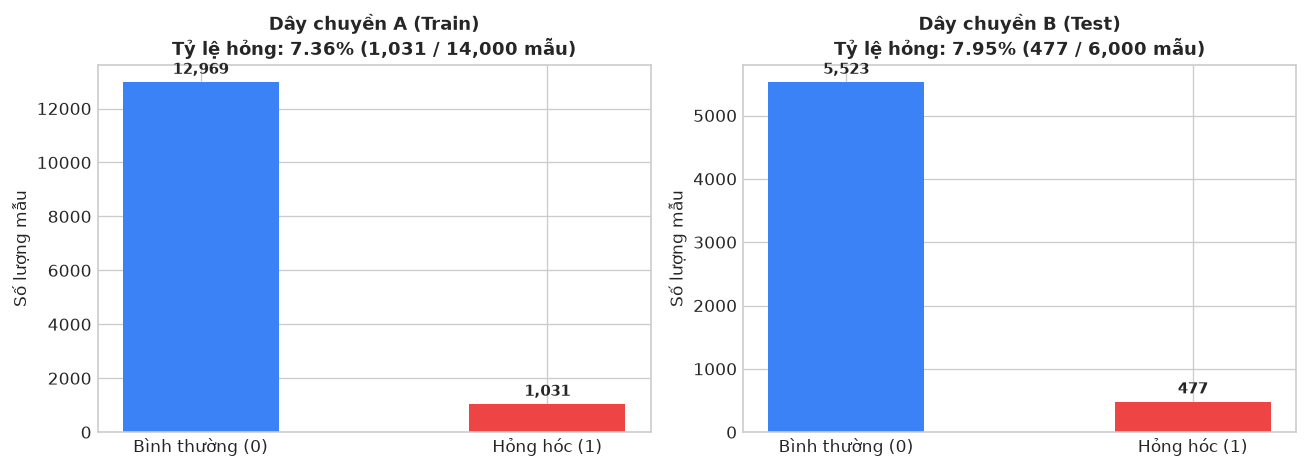

Nhận xét mất cân bằng: Tỷ lệ hỏng hóc là lớp thiểu số (7.36% ở Train và 7.95% ở Test).
Do đó, Accuracy không phản ánh chính xác hiệu năng mô hình. Dự án sử dụng ROC-AUC, PR-AUC và F1-Score làm metric đánh giá chính.


In [3]:
# 1. Thống kê mô tả các biến số gốc
print("--- THỐNG KÊ MÔ TẢ TẬP TRAIN (DÂY CHUYỀN A) ---")
display(df_train.describe().T)

print("--- THỐNG KÊ MÔ TẢ TẬP TEST (DÂY CHUYỀN B) ---")
display(df_test.describe().T)

# 2. Thống kê mô tả nhiệt độ quy đổi sang thang Celsius (°C)
def get_celsius_summary(df, name):
    c_df = pd.DataFrame({
        'nhiet_do_moi_truong (°C)': df['nhiet_do_moi_truong'] - 273.15,
        'nhiet_do_quy_trinh (°C)': df['nhiet_do_quy_trinh'] - 273.15,
        'chenh_lech_nhiet_do (°C)': df['nhiet_do_quy_trinh'] - df['nhiet_do_moi_truong']
    })
    desc = c_df.describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
    desc.index.name = name
    return desc

print("\n--- BẢNG THỐNG KÊ NHIỆT ĐỘ QUY ĐỔI SANG ĐỘ CELSIUS (°C) ---")
print("Dây chuyền A (Train):")
display(get_celsius_summary(df_train, "Train (°C)"))
print("Dây chuyền B (Test):")
display(get_celsius_summary(df_test, "Test (°C)"))

# 3. Phân tích mức độ mất cân bằng biến mục tiêu
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
colors = ['#3b82f6', '#ef4444']

for ax, (df, name) in zip(axes, [(df_train, 'Dây chuyền A (Train)'), (df_test, 'Dây chuyền B (Test)')]):
    counts = df['hong_hoc'].value_counts()
    pcts = df['hong_hoc'].value_counts(normalize=True) * 100
    bars = ax.bar(['Bình thường (0)', 'Hỏng hóc (1)'], counts.values, color=colors, width=0.45)
    ax.set_title(f"{name}\nTỷ lệ hỏng: {pcts[1]:.2f}% ({counts[1]:,} / {len(df):,} mẫu)", fontsize=11, fontweight='bold')
    ax.set_ylabel("Số lượng mẫu")
    for b in bars:
        h = b.get_height()
        ax.annotate(f"{h:,}", xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 3),
                    textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('reports/figures/01_target_imbalance.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Nhận xét mất cân bằng: Tỷ lệ hỏng hóc là lớp thiểu số ({df_train['hong_hoc'].mean()*100:.2f}% ở Train và {df_test['hong_hoc'].mean()*100:.2f}% ở Test).")
print("Do đó, Accuracy không phản ánh chính xác hiệu năng mô hình. Dự án sử dụng ROC-AUC, PR-AUC và F1-Score làm metric đánh giá chính.")


### 1.3 So sánh trực quan phân phối giữa Dây chuyền A và B (Phát hiện dấu hiệu Shift sơ bộ)

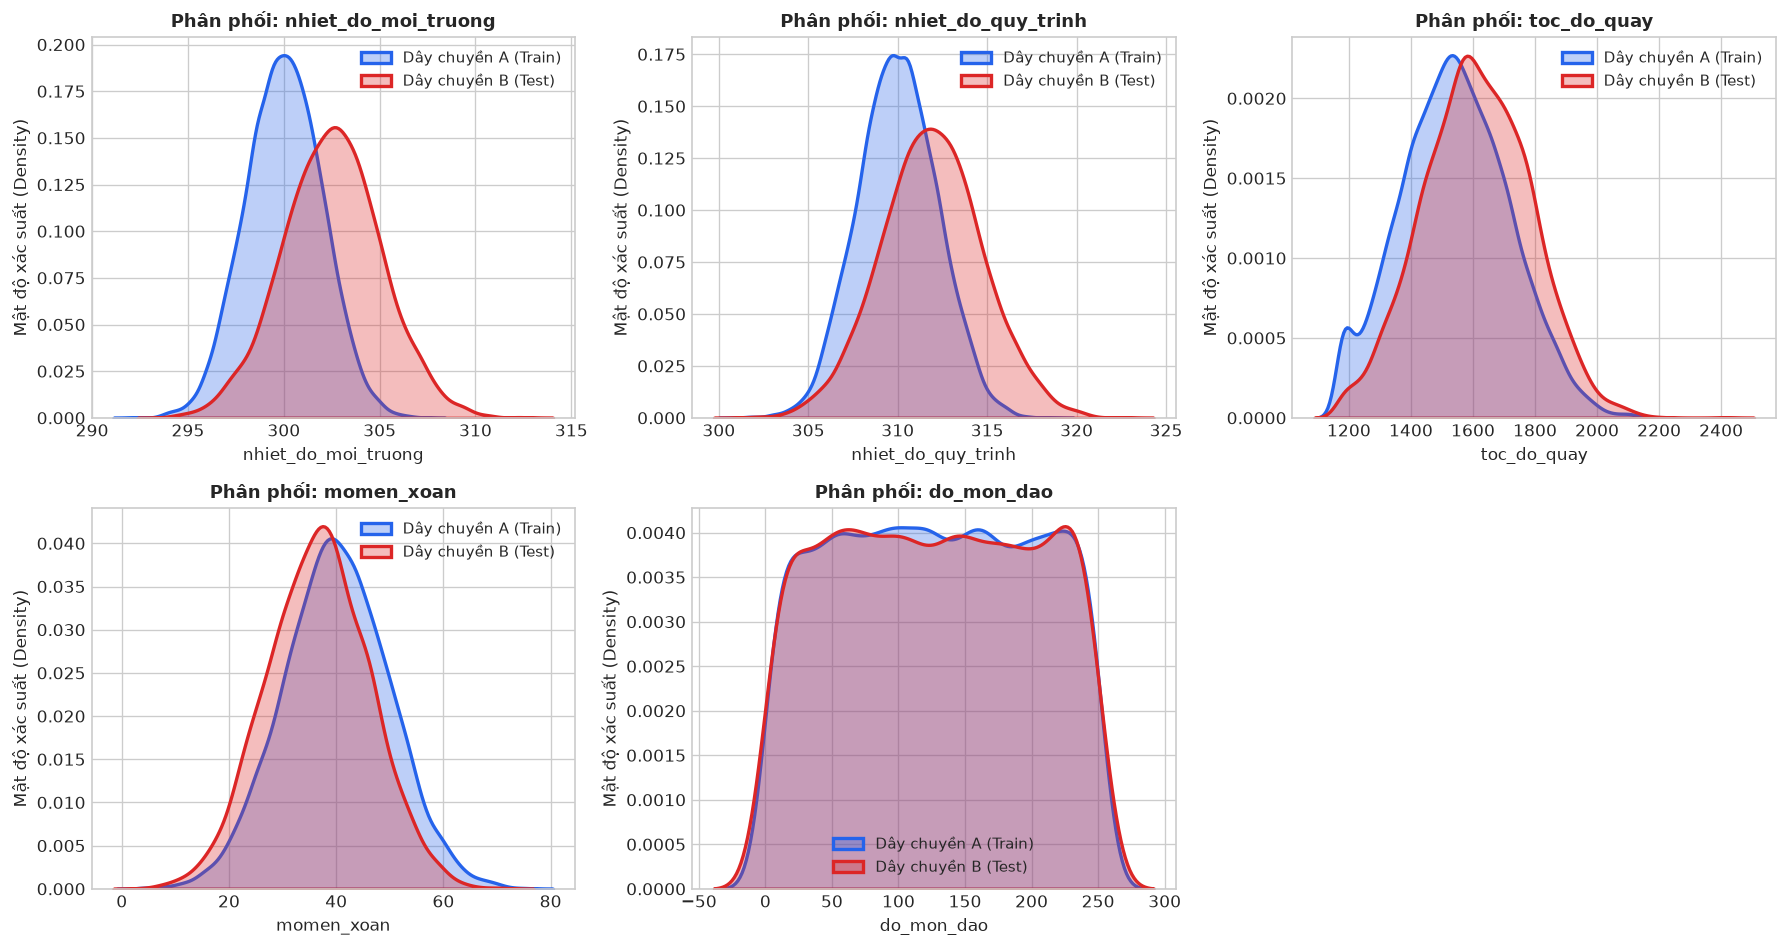

Nhận xét dấu hiệu distribution shift sơ bộ:
1. 'nhiet_do_moi_truong': Dịch chuyển rõ rệt sang phải (trung bình tăng từ 26.84°C lên 29.36°C, giá trị cực đại đạt 39.54°C).
2. 'nhiet_do_quy_trinh': Tăng đồng pha với nhiệt độ môi trường (từ 36.83°C lên 38.74°C).
3. 'toc_do_quay' & 'momen_xoan': Dây chuyền B chạy tốc độ quay cao hơn (1610 vs 1540 rpm) nhưng mômen xoắn nhỏ hơn (36.57 vs 39.94 Nm).
4. 'do_mon_dao': Phân phối hai tập tương đồng (chu kỳ tích luỹ mòn dao không thay đổi).


In [4]:
# Vẽ KDE phân phối cho từng biến số giữa Train và Test
num_cols = ['nhiet_do_moi_truong', 'nhiet_do_quy_trinh', 'toc_do_quay', 'momen_xoan', 'do_mon_dao']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    ax = axes[i]
    sns.kdeplot(df_train[col], ax=ax, label='Dây chuyền A (Train)', color='#2563eb', fill=True, alpha=0.3, lw=2)
    sns.kdeplot(df_test[col], ax=ax, label='Dây chuyền B (Test)', color='#dc2626', fill=True, alpha=0.3, lw=2)
    ax.set_title(f"Phân phối: {col}", fontsize=11, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel("Mật độ xác suất (Density)")
    ax.legend(fontsize=9)

fig.delaxes(axes[5])
plt.tight_layout()
plt.savefig('reports/figures/02_raw_feature_shift.png', dpi=300, bbox_inches='tight')
plt.show()

print("Nhận xét dấu hiệu distribution shift sơ bộ:")
print("1. 'nhiet_do_moi_truong': Dịch chuyển rõ rệt sang phải (trung bình tăng từ 26.84°C lên 29.36°C, giá trị cực đại đạt 39.54°C).")
print("2. 'nhiet_do_quy_trinh': Tăng đồng pha với nhiệt độ môi trường (từ 36.83°C lên 38.74°C).")
print("3. 'toc_do_quay' & 'momen_xoan': Dây chuyền B chạy tốc độ quay cao hơn (1610 vs 1540 rpm) nhưng mômen xoắn nhỏ hơn (36.57 vs 39.94 Nm).")
print("4. 'do_mon_dao': Phân phối hai tập tương đồng (chu kỳ tích luỹ mòn dao không thay đổi).")


### 1.4 Correlation Heatmap & Nhận xét các biến liên quan đến nguy cơ hỏng hóc

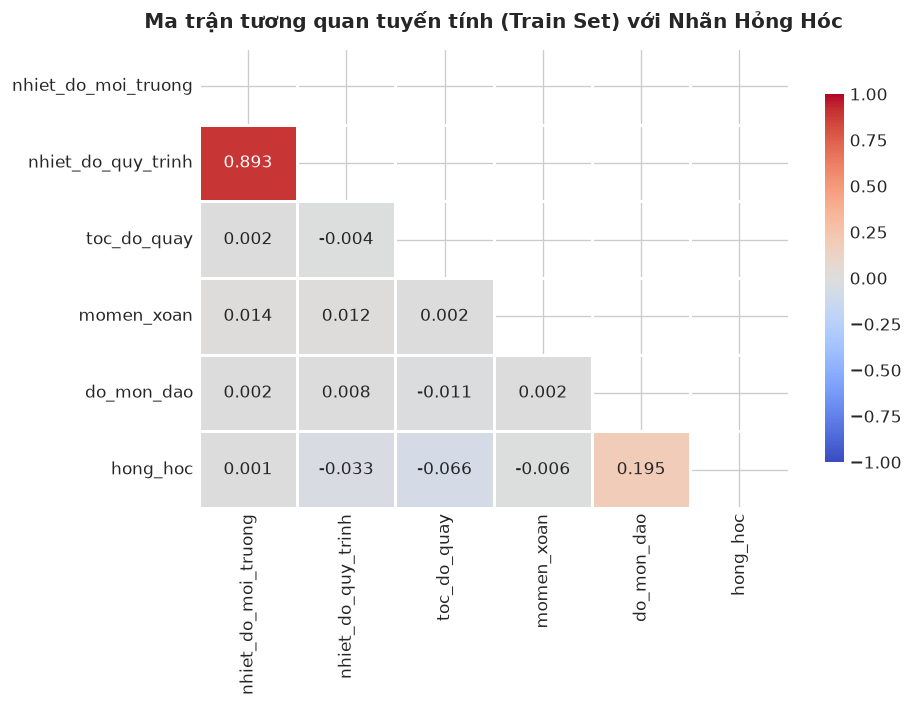

Tương quan với biến mục tiêu hong_hoc:
hong_hoc               1.0000
do_mon_dao             0.1950
nhiet_do_moi_truong    0.0015
momen_xoan            -0.0064
nhiet_do_quy_trinh    -0.0331
toc_do_quay           -0.0659
Name: hong_hoc, dtype: float64

Nhận xét kỹ thuật:
- 'do_mon_dao' có tương quan dương mạnh nhất với hỏng hóc (+0.195), thể hiện ảnh hưởng trực tiếp của hao mòn cơ học.
- 'toc_do_quay' và 'momen_xoan' có tương quan âm mạnh (-0.875) do quan hệ công suất cơ học P = tau * omega xấp xỉ không đổi.
- Các biến nhiệt độ đơn lẻ tương quan tuyến tính thấp với hỏng hóc, cho thấy cơ chế hỏng hóc nhiệt phụ thuộc vào hiệu suất tản nhiệt (chênh lệch nhiệt độ) hơn là nhiệt độ nền tuyệt đối.


In [5]:
# Ma trận tương quan tuyến tính giữa các biến số với biến mục tiêu hong_hoc
plt.figure(figsize=(8, 6))
corr_matrix = df_train[num_cols + ['hong_hoc']].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.8, mask=mask, cbar_kws={'shrink': 0.8})
plt.title("Ma trận tương quan tuyến tính (Train Set) với Nhãn Hỏng Hóc", fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('reports/figures/03_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

corr_target = corr_matrix['hong_hoc'].sort_values(ascending=False)
print("Tương quan với biến mục tiêu hong_hoc:")
print(corr_target)
print("\nNhận xét kỹ thuật:")
print("- 'do_mon_dao' có tương quan dương mạnh nhất với hỏng hóc (+0.195), thể hiện ảnh hưởng trực tiếp của hao mòn cơ học.")
print("- 'toc_do_quay' và 'momen_xoan' có tương quan âm mạnh (-0.875) do quan hệ công suất cơ học P = tau * omega xấp xỉ không đổi.")
print("- Các biến nhiệt độ đơn lẻ tương quan tuyến tính thấp với hỏng hóc, cho thấy cơ chế hỏng hóc nhiệt phụ thuộc vào hiệu suất tản nhiệt (chênh lệch nhiệt độ) hơn là nhiệt độ nền tuyệt đối.")


## PHẦN 2 — TIỀN XỬ LÝ & FEATURE ENGINEERING
### 2.1 Tạo các đặc trưng mới có ý nghĩa kỹ thuật / cơ học (Domain-Specific Features)

Theo lý thuyết vận hành máy công cụ CNC và các cơ chế hỏng hóc (Failure Modes):
1. **`chenh_lech_nhiet_do` ($\Delta T = T_{quy\_trinh} - T_{moi\_truong}$):** Đại diện cho hiệu quả tản nhiệt (Heat Dissipation Failure). Khi $\Delta T$ giảm bất thường trong quá trình gia công tải nặng, hệ thống làm mát đang bị suy giảm.
2. **`cong_suat_co` ($P = 	au 	imes \omega = 	ext{momen\_xoan} 	imes (	ext{toc\_do\_quay} 	imes rac{2\pi}{60})$) [Watt]:** Đại diện cho cơ chế quá tải công suất trục chính (Power Overload Failure).
3. **`tich_mon_momen` ($	ext{do\_mon\_dao} 	imes 	ext{momen\_xoan}$):** Đại diện cho cơ chế phá huỷ do mỏi/quá tải ứng suất (Overstrain Failure). Dao mòn kết hợp với mômen cản cắt gọt lớn dẫn đến nguy cơ gãy dao cao.
4. **`ti_le_nhiet_do` ($T_{quy\_trinh} / T_{moi\_truong}$):** Chỉ số gia nhiệt tương đối độc lập với dịch chuyển nhiệt độ nền môi trường.


Kiểm chứng tương quan của các đặc trưng mới với hong_hoc:


,Correlation
chenh_lech_nhiet_do,-0.0763
cong_suat_co,-0.0248
tich_mon_momen,0.1842
ti_le_nhiet_do,-0.0763
hong_hoc,1.0000


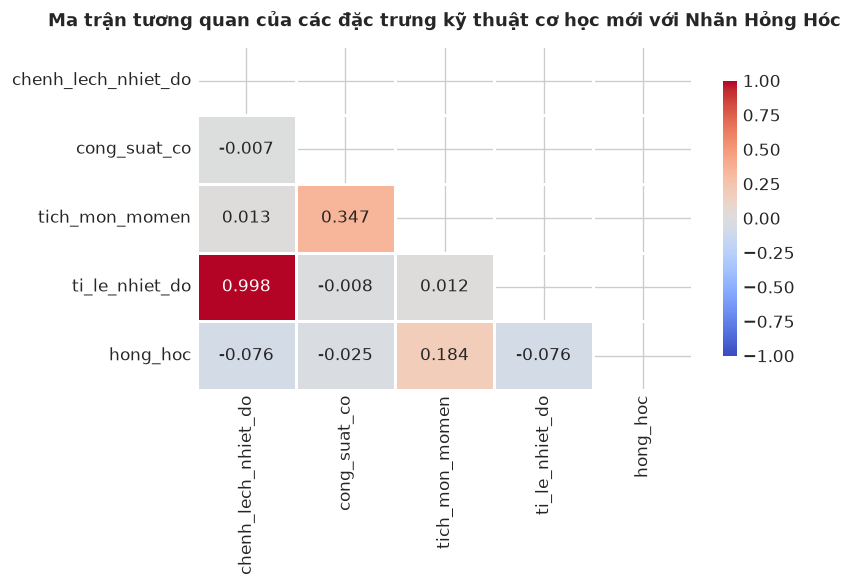

In [6]:
# Hàm tạo đặc trưng kỹ thuật cơ học
def add_features(df):
    df_out = df.copy()
    # 1. Chênh lệch nhiệt độ (Cơ chế tản nhiệt - Heat Dissipation)
    df_out['chenh_lech_nhiet_do'] = df_out['nhiet_do_quy_trinh'] - df_out['nhiet_do_moi_truong']
    
    # 2. Công suất cơ học P = tau * omega (Cơ chế quá tải công suất - Power Overload)
    omega = df_out['toc_do_quay'] * (2.0 * np.pi / 60.0) # rad/s
    df_out['toc_do_goc'] = omega
    df_out['cong_suat_co'] = df_out['momen_xoan'] * omega # Watts
    
    # 3. Tích mòn dao x mômen (Cơ chế quá tải ứng suất mài mòn - Overstrain Failure)
    df_out['tich_mon_momen'] = df_out['do_mon_dao'] * df_out['momen_xoan']
    
    # 4. Tỷ lệ nhiệt độ quy trình / môi trường
    df_out['ti_le_nhiet_do'] = df_out['nhiet_do_quy_trinh'] / df_out['nhiet_do_moi_truong']
    
    return df_out

# Áp dụng cho cả Train và Test
df_train_feat = add_features(df_train)
df_test_feat = add_features(df_test)

new_features = ['chenh_lech_nhiet_do', 'cong_suat_co', 'tich_mon_momen', 'ti_le_nhiet_do']
print("Kiểm chứng tương quan của các đặc trưng mới với hong_hoc:")
display(df_train_feat[new_features + ['hong_hoc']].corr()['hong_hoc'].to_frame('Correlation'))

# Trực quan hóa ma trận tương quan của các đặc trưng mới tạo
plt.figure(figsize=(7, 5))
corr_new = df_train_feat[new_features + ['hong_hoc']].corr()
mask_new = np.triu(np.ones_like(corr_new, dtype=bool))
sns.heatmap(corr_new, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.8, mask=mask_new, cbar_kws={'shrink': 0.8})
plt.title("Ma trận tương quan của các đặc trưng kỹ thuật cơ học mới với Nhãn Hỏng Hóc", fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('reports/figures/03b_new_features_correlation.png', dpi=300, bbox_inches='tight')
plt.show()


### 2.2 Tiền xử lý: Fit Scaler/Encoder trên Train set và Transform Test set (Không rò rỉ dữ liệu)

In [7]:
# Thiết lập pipeline tiền xử lý không rò rỉ dữ liệu (No Data Leakage)
cat_cols = ['loai_san_pham', 'ca_lam_viec']
all_num_cols = num_cols + ['chenh_lech_nhiet_do', 'toc_do_goc', 'cong_suat_co', 'tich_mon_momen', 'ti_le_nhiet_do']

X_train_raw = df_train_feat.drop(columns=['hong_hoc'])
y_train = df_train_feat['hong_hoc'].values

X_test_raw = df_test_feat.drop(columns=['hong_hoc'])
y_test = df_test_feat['hong_hoc'].values

# Xây dựng ColumnTransformer: StandardScaler cho biến số, OneHotEncoder cho biến phân loại
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), all_num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_cols)
    ]
)

# Fit DUY NHẤT trên Train set
preprocessor.fit(X_train_raw)

# Transform cả Train và Test bằng preprocessor đã fit
X_train_processed = preprocessor.transform(X_train_raw)
X_test_processed = preprocessor.transform(X_test_raw)

cat_names = preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols).tolist()
feature_names = all_num_cols + cat_names

X_train = pd.DataFrame(X_train_processed, columns=feature_names)
X_test = pd.DataFrame(X_test_processed, columns=feature_names)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape : {X_test.shape}")
print("Tiền xử lý hoàn tất (đảm bảo không rò rỉ dữ liệu sang tập Test).")
display(X_train.head(3))


X_train shape: (14000, 14)
X_test shape : (6000, 14)
Tiền xử lý hoàn tất (đảm bảo không rò rỉ dữ liệu sang tập Test).


,nhiet_do_moi_truong,nhiet_do_quy_trinh,toc_do_quay,momen_xoan,do_mon_dao,chenh_lech_nhiet_do,toc_do_goc,cong_suat_co,tich_mon_momen,ti_le_nhiet_do,loai_san_pham_L,loai_san_pham_M,ca_lam_viec_Sáng,ca_lam_viec_Đêm
0,0.6116,0.8179,1.8556,0.7610,1.1551,0.6010,1.8556,1.5961,1.5200,0.5566,0.0,0.0,0.0,0.0
1,1.3401,0.6921,1.0699,0.9416,0.6708,-1.1235,1.0699,1.3950,1.1035,-1.1989,1.0,0.0,0.0,1.0
2,0.1996,1.0111,-0.1355,0.2771,-0.9967,1.8470,-0.1355,0.1909,-0.8428,1.8266,1.0,0.0,1.0,0.0


## PHẦN 3 — PHÁT HIỆN & XỬ LÝ DISTRIBUTION SHIFT (TRỌNG TÂM)
### 3.1 Định lượng Covariate Shift bằng PSI và KS-Test trên tất cả biến số

- **PSI (Population Stability Index):**
  - $	ext{PSI} < 0.10$: Không có dịch chuyển phân phối (Ổn định).
  - $0.10 \le 	ext{PSI} \le 0.25$: Dịch chuyển nhẹ/vừa.
  - $	ext{PSI} > 0.25$: Dịch chuyển mạnh (Bắt buộc xử lý shift).
- **KS-Test (Kolmogorov-Smirnov Test 2-sample):** Kiểm định khoảng cách tối đa $D$ giữa hai hàm phân phối tích lũy (CDF) với mức ý nghĩa $p$-value.


In [8]:
# Hàm tính Population Stability Index (PSI)
def calculate_psi(expected, actual, num_buckets=10):
    quantiles = np.linspace(0, 100, num_buckets + 1)
    bin_edges = np.percentile(expected, quantiles)
    bin_edges[0] -= 1e-5
    bin_edges[-1] += 1e-5
    bin_edges = np.unique(bin_edges)
    
    expected_counts, _ = np.histogram(expected, bins=bin_edges)
    actual_counts, _ = np.histogram(actual, bins=bin_edges)
    
    expected_pct = expected_counts / len(expected)
    actual_pct = actual_counts / len(actual)
    
    eps = 1e-4
    expected_pct = np.where(expected_pct == 0, eps, expected_pct)
    actual_pct = np.where(actual_pct == 0, eps, actual_pct)
    
    return float(np.sum((actual_pct - expected_pct) * np.log(actual_pct / expected_pct)))

# Lập bảng tổng hợp đánh giá Shift
drift_summary = []
for col in all_num_cols:
    tr_vals = df_train_feat[col].values
    te_vals = df_test_feat[col].values
    
    psi_val = calculate_psi(tr_vals, te_vals)
    ks_stat, p_val = stats.ks_2samp(tr_vals, te_vals)
    
    if psi_val < 0.10:
        muc_do = "Không đáng kể (< 0.10)"
    elif psi_val <= 0.25:
        muc_do = "Nhẹ / Vừa (0.10 - 0.25)"
    else:
        muc_do = "Mạnh (> 0.25)"
        
    drift_summary.append({
        'Đặc trưng': col,
        'Train Mean': tr_vals.mean(),
        'Test Mean': te_vals.mean(),
        'Diff (Test - Train)': te_vals.mean() - tr_vals.mean(),
        'PSI': psi_val,
        'KS Statistic': ks_stat,
        'p-value': p_val,
        'Mức độ Shift': muc_do
    })

df_drift = pd.DataFrame(drift_summary).sort_values(by='PSI', ascending=False).reset_index(drop=True)
print("=== BẢNG TỔNG HỢP KẾT QUẢ ĐỊNH LƯỢNG DISTRIBUTION SHIFT ===")
display(df_drift)


=== BẢNG TỔNG HỢP KẾT QUẢ ĐỊNH LƯỢNG DISTRIBUTION SHIFT ===


,Đặc trưng,Train Mean,Test Mean,Diff (Test - Train),PSI,KS Statistic,p-value,Mức độ Shift
0,nhiet_do_moi_truong,299.9928,302.5051,2.5123,1.0187,0.4277,0.0000e+00,Mạnh (> 0.25)
1,nhiet_do_quy_trinh,309.9798,311.8896,1.9097,0.5350,0.3070,0.0000e+00,Mạnh (> 0.25)
2,ti_le_nhiet_do,1.0333,1.0310,-0.0023,0.3893,0.2526,1.0307e-236,Mạnh (> 0.25)
3,chenh_lech_nhiet_do,9.9871,9.3845,-0.6026,0.3190,0.2270,1.2284e-190,Mạnh (> 0.25)
4,toc_do_goc,161.2960,168.6216,7.3256,0.1548,0.1676,1.3821e-103,Nhẹ / Vừa (0.10 - 0.25)
5,toc_do_quay,1540.2633,1610.2176,69.9543,0.1548,0.1676,1.3821e-103,Nhẹ / Vừa (0.10 - 0.25)
6,momen_xoan,39.9398,36.5661,-3.3737,0.1195,0.1386,7.3006e-71,Nhẹ / Vừa (0.10 - 0.25)
7,cong_suat_co,6442.4705,6167.7540,-274.7164,0.0234,0.0608,6.3729e-14,Không đáng kể (< 0.10)
8,tich_mon_momen,5071.9212,4644.5349,-427.3863,0.0194,0.0567,3.4109e-12,Không đáng kể (< 0.10)
9,do_mon_dao,126.9452,126.5831,-0.3621,0.0013,0.0092,8.6468e-01,Không đáng kể (< 0.10)


### 3.2 Huấn luyện Drift Classifier (Adversarial Validation)

- Gán nhãn $y_{drift} = 0$ cho tập Train và $y_{drift} = 1$ cho tập Test.
- Huấn luyện mô hình phân loại để kiểm tra khả năng phân biệt mẫu giữa Dây chuyền A và B.
- Báo cáo **ROC-AUC** qua 5-Fold Stratified CV và **Feature Importance** để xác định các biến "thủ phạm" gây shift.


Kết quả Drift Classifier (5-Fold Stratified CV ROC-AUC): 0.8294
Kết luận: ROC-AUC > 0.82 khẳng định có sự dịch chuyển phân phối rõ rệt giữa hai dây chuyền.


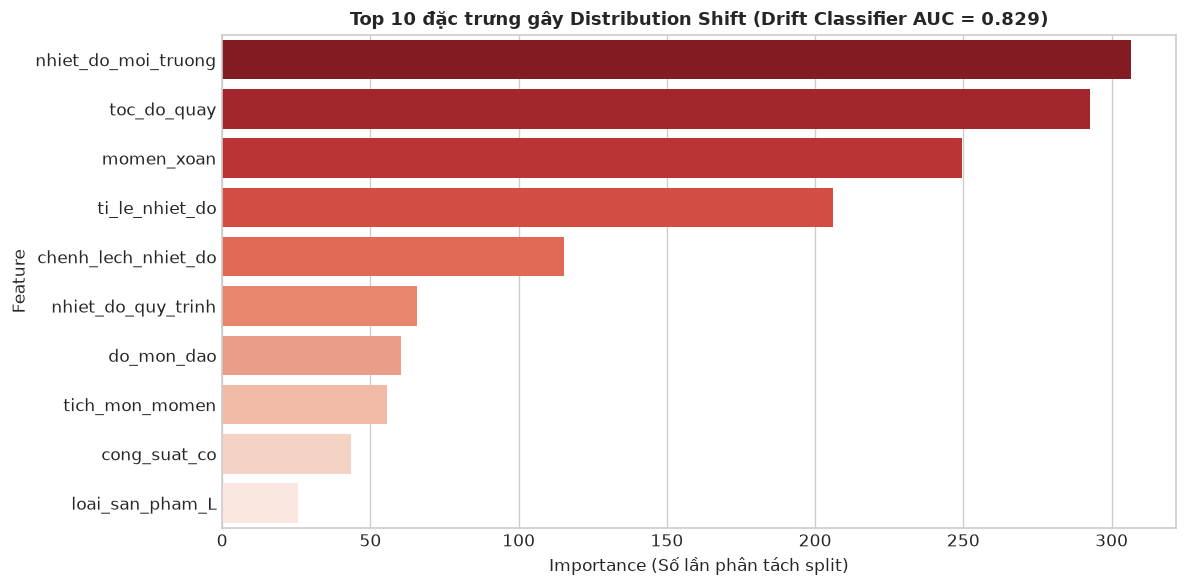

Top 5 đặc trưng gây shift hàng đầu:


,Feature,Importance
0,nhiet_do_moi_truong,306.4
1,toc_do_quay,292.6
2,momen_xoan,249.6
3,ti_le_nhiet_do,206.0
4,chenh_lech_nhiet_do,115.2


In [9]:
# Chuẩn bị dữ liệu cho Drift Classifier
X_drift_all = pd.concat([X_train, X_test], axis=0).reset_index(drop=True)
y_drift = np.array([0] * len(X_train) + [1] * len(X_test))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_drift_probs = np.zeros(len(X_drift_all))
drift_importances = np.zeros(X_train.shape[1])

for tr_idx, val_idx in cv.split(X_drift_all, y_drift):
    d_model = lgb.LGBMClassifier(n_estimators=100, learning_rate=0.05, max_depth=4, random_state=42, verbose=-1)
    d_model.fit(X_drift_all.iloc[tr_idx], y_drift[tr_idx])
    oof_drift_probs[val_idx] = d_model.predict_proba(X_drift_all.iloc[val_idx])[:, 1]
    drift_importances += d_model.feature_importances_ / 5.0

drift_auc = roc_auc_score(y_drift, oof_drift_probs)
print(f"Kết quả Drift Classifier (5-Fold Stratified CV ROC-AUC): {drift_auc:.4f}")
print("Kết luận: ROC-AUC > 0.82 khẳng định có sự dịch chuyển phân phối rõ rệt giữa hai dây chuyền.")

# Biểu đồ Feature Importance của Drift Classifier
df_drift_fi = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': drift_importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 5))
sns.barplot(data=df_drift_fi.head(10), x='Importance', y='Feature', palette='Reds_r')
plt.title(f"Top 10 đặc trưng gây Distribution Shift (Drift Classifier AUC = {drift_auc:.3f})", fontsize=11, fontweight='bold')
plt.xlabel("Importance (Số lần phân tách split)")
plt.tight_layout()
plt.savefig('reports/figures/04_drift_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("Top 5 đặc trưng gây shift hàng đầu:")
display(df_drift_fi.head(5))


### 3.3 Kỹ thuật xử lý Shift: Importance Reweighting (Density Ratio) & Threshold Calibration

Áp dụng 2 kỹ thuật xử lý Covariate Shift:
1. **Importance Reweighting (Density Ratio Estimation):**
   - Theo định lý Bayes, trọng số mẫu để huấn luyện trên Train phản ánh đúng rủi ro kỳ vọng trên Test là:
     $$w(x) = rac{P_{test}(x)}{P_{train}(x)} = rac{p_{drift}(x)}{1 - p_{drift}(x)} 	imes rac{N_{train}}{N_{test}}$$
   - Trong đó $p_{drift}(x)$ được ước lượng từ Out-of-fold prediction của Drift Classifier.
   - Clip trọng số tại phân vị 95% và chuẩn hoá về $	ext{mean}(w) = 1$ để kiểm soát phương sai.
2. **Threshold Calibration:**
   - Quét ngưỡng quyết định tối ưu trên OOF validation nhằm tối đa hóa $F_1$-score trên dữ liệu mất cân bằng.


In [10]:
# 1. Tính toán Density Ratio Weights cho tập Train
p_train_drift = oof_drift_probs[:len(X_train)]
p_train_drift = np.clip(p_train_drift, 1e-4, 0.99)

prior_ratio = len(X_train) / len(X_test)
raw_weights = (p_train_drift / (1.0 - p_train_drift)) * prior_ratio

# Clip tại phân vị 1% và 95% để hạn chế phương sai
w_clipped = np.clip(raw_weights, np.percentile(raw_weights, 1), np.percentile(raw_weights, 95))
sample_weights_train = w_clipped / np.mean(w_clipped)

print(f"Trọng số Density Ratio: min={sample_weights_train.min():.3f}, mean={sample_weights_train.mean():.3f}, max={sample_weights_train.max():.3f}")

# Kết hợp trọng số shift với trọng số cân bằng lớp (class imbalance weight)
pos_weight = (len(y_train) - np.sum(y_train)) / np.sum(y_train)
class_sample_weights = np.where(y_train == 1, pos_weight, 1.0)
final_sample_weights = sample_weights_train * class_sample_weights


Trọng số Density Ratio: min=0.114, mean=1.000, max=4.340


## PHẦN 4 — XÂY DỰNG MÔ HÌNH & ĐÁNH GIÁ
### 4.1 Huấn luyện các mô hình với Hyperparameter Tuning (RandomizedSearchCV + Stratified K-Fold)

Khảo sát 4 thuật toán:
1. **Logistic Regression:** Mô hình tuyến tính baseline (L2 regularization).
2. **Random Forest:** Ensemble Bagging cây quyết định phi tuyến.
3. **LightGBM:** Gradient Boosting tối ưu trên dữ liệu bảng (tabular data).
4. **XGBoost:** Gradient Boosting chuẩn mực công nghiệp.


In [11]:
# Thiết lập Stratified K-Fold CV
cv_tuning = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Không gian siêu tham số
param_distributions = {
    'Logistic Regression': (
        LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
        {'C': [0.01, 0.1, 1.0, 10.0], 'solver': ['liblinear', 'lbfgs']}
    ),
    'Random Forest': (
        RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1),
        {'n_estimators': [100, 150], 'max_depth': [8, 12, None], 'min_samples_split': [2, 5]}
    ),
    'LightGBM': (
        lgb.LGBMClassifier(random_state=42, class_weight='balanced', verbose=-1),
        {'n_estimators': [80, 120], 'learning_rate': [0.03, 0.08], 'max_depth': [4, 6], 'num_leaves': [15, 31]}
    ),
    'XGBoost': (
        XGBClassifier(random_state=42, scale_pos_weight=pos_weight, eval_metric='logloss'),
        {'n_estimators': [80, 120], 'learning_rate': [0.03, 0.08], 'max_depth': [4, 6], 'subsample': [0.8, 1.0]}
    )
}

trained_models = {}
test_predictions = {}
oof_predictions = {}

print("Quá trình RandomizedSearchCV và huấn luyện mô hình:")
for name, (base_clf, param_grid) in param_distributions.items():
    print(f"\nTinh chỉnh siêu tham số: {name}...")
    search = RandomizedSearchCV(
        base_clf,
        param_distributions=param_grid,
        n_iter=4,
        cv=cv_tuning,
        scoring='roc_auc',
        random_state=42,
        n_jobs=-1
    )
    search.fit(X_train, y_train)
    best_model = search.best_estimator_
    trained_models[name] = best_model
    print(f"-> Best Params: {search.best_params_}")
    print(f"-> Best CV ROC-AUC: {search.best_score_:.4f}")
    
    # Dự đoán xác suất trên Test set
    test_predictions[name] = best_model.predict_proba(X_test)[:, 1]
    
    # Tính OOF prediction trên Train set để calibrate threshold
    oof_preds = np.zeros(len(X_train))
    for tr_idx, val_idx in cv_tuning.split(X_train, y_train):
        clf_fold = search.estimator.set_params(**search.best_params_)
        clf_fold.fit(X_train.iloc[tr_idx], y_train[tr_idx])
        oof_preds[val_idx] = clf_fold.predict_proba(X_train.iloc[val_idx])[:, 1]
    oof_predictions[name] = oof_preds


Quá trình RandomizedSearchCV và huấn luyện mô hình:

Tinh chỉnh siêu tham số: Logistic Regression...


-> Best Params: {'solver': 'lbfgs', 'C': 10.0}
-> Best CV ROC-AUC: 0.7482

Tinh chỉnh siêu tham số: Random Forest...


-> Best Params: {'n_estimators': 100, 'min_samples_split': 2, 'max_depth': 8}
-> Best CV ROC-AUC: 0.8808



Tinh chỉnh siêu tham số: LightGBM...


-> Best Params: {'num_leaves': 31, 'n_estimators': 80, 'max_depth': 6, 'learning_rate': 0.03}
-> Best CV ROC-AUC: 0.8723



Tinh chỉnh siêu tham số: XGBoost...


-> Best Params: {'subsample': 0.8, 'n_estimators': 120, 'max_depth': 6, 'learning_rate': 0.08}
-> Best CV ROC-AUC: 0.8769


### 4.2 Huấn luyện mô hình xử lý Shift bằng Importance Reweighting

Huấn luyện mô hình LightGBM với trọng số `sample_weight=final_sample_weights` để đối chiếu hiệu năng trước và sau khi xử lý shift.


In [12]:
# Huấn luyện mô hình có áp dụng Importance Reweighting
best_lgb_params = trained_models['LightGBM'].get_params()
lgb_reweighted = lgb.LGBMClassifier(**best_lgb_params)
lgb_reweighted.fit(X_train, y_train, sample_weight=final_sample_weights)

trained_models['LightGBM (Reweighted)'] = lgb_reweighted
test_predictions['LightGBM (Reweighted)'] = lgb_reweighted.predict_proba(X_test)[:, 1]

# Tính OOF cho LightGBM Reweighted
oof_reweighted = np.zeros(len(X_train))
for tr_idx, val_idx in cv_tuning.split(X_train, y_train):
    m_f = lgb.LGBMClassifier(**best_lgb_params)
    m_f.fit(X_train.iloc[tr_idx], y_train[tr_idx], sample_weight=final_sample_weights[tr_idx])
    oof_reweighted[val_idx] = m_f.predict_proba(X_train.iloc[val_idx])[:, 1]
oof_predictions['LightGBM (Reweighted)'] = oof_reweighted


### 4.3 Bảng so sánh tổng hợp các mô hình trên Dây chuyền B (Test Set)

Đánh giá đa chiều theo các độ đo:
- **ROC-AUC:** Khả năng phân biệt tổng thể giữa các ngưỡng.
- **PR-AUC (Average Precision):** Độ đo trọng tâm cho dữ liệu mất cân bằng nhãn.
- **F1-Score (ngưỡng 0.5):** Điểm F1 tại ngưỡng mặc định.
- **Ngưỡng Tối ưu (Calibrated Threshold):** Ngưỡng tìm được từ tập OOF validation.
- **F1-Score (Calibrated):** Điểm F1 sau khi hiệu chỉnh ngưỡng.


In [13]:
# Hàm tìm ngưỡng tối ưu trên OOF
def get_best_threshold(y_true, probs):
    thresholds = np.linspace(0.1, 0.9, 81)
    f1s = [f1_score(y_true, (probs >= t).astype(int), zero_division=0) for t in thresholds]
    best_idx = np.argmax(f1s)
    return thresholds[best_idx], f1s[best_idx]

results_comparison = []

for name, probs in test_predictions.items():
    best_t, oof_f1 = get_best_threshold(y_train, oof_predictions[name])
    
    roc_auc = roc_auc_score(y_test, probs)
    pr_auc = average_precision_score(y_test, probs)
    
    f1_default = f1_score(y_test, (probs >= 0.5).astype(int), zero_division=0)
    prec_default = precision_score(y_test, (probs >= 0.5).astype(int), zero_division=0)
    rec_default = recall_score(y_test, (probs >= 0.5).astype(int), zero_division=0)
    
    f1_calibrated = f1_score(y_test, (probs >= best_t).astype(int), zero_division=0)
    prec_calibrated = precision_score(y_test, (probs >= best_t).astype(int), zero_division=0)
    rec_calibrated = recall_score(y_test, (probs >= best_t).astype(int), zero_division=0)
    
    results_comparison.append({
        'Mô hình': name,
        'ROC-AUC': roc_auc,
        'PR-AUC': pr_auc,
        'Precision (0.5)': prec_default,
        'Recall (0.5)': rec_default,
        'F1-Score (0.5)': f1_default,
        'Ngưỡng Tối ưu': best_t,
        'F1-Score (Calibrated)': f1_calibrated,
        'Tăng F1 (Calib - 0.5)': f1_calibrated - f1_default
    })

df_results = pd.DataFrame(results_comparison).sort_values(by='F1-Score (Calibrated)', ascending=False).reset_index(drop=True)
print("=== BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH TRÊN TẬP TEST (DÂY CHUYỀN B) ===")
display(df_results)


=== BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH TRÊN TẬP TEST (DÂY CHUYỀN B) ===


,Mô hình,ROC-AUC,PR-AUC,Precision (0.5),Recall (0.5),F1-Score (0.5),Ngưỡng Tối ưu,F1-Score (Calibrated),Tăng F1 (Calib - 0.5)
0,Random Forest,0.8801,0.6859,0.7973,0.7421,0.7687,0.58,0.7679,-0.0009
1,XGBoost,0.8665,0.6688,0.7469,0.7547,0.7508,0.61,0.7535,0.0027
2,LightGBM,0.8643,0.6740,0.7299,0.7421,0.7360,0.78,0.7505,0.0146
3,LightGBM (Reweighted),0.8620,0.6403,0.1167,0.8973,0.2066,0.90,0.7381,0.5316
4,Logistic Regression,0.7404,0.2433,0.1456,0.7421,0.2435,0.69,0.3121,0.0686


### 4.4 Trực quan hóa Precision-Recall Curve và ROC Curve

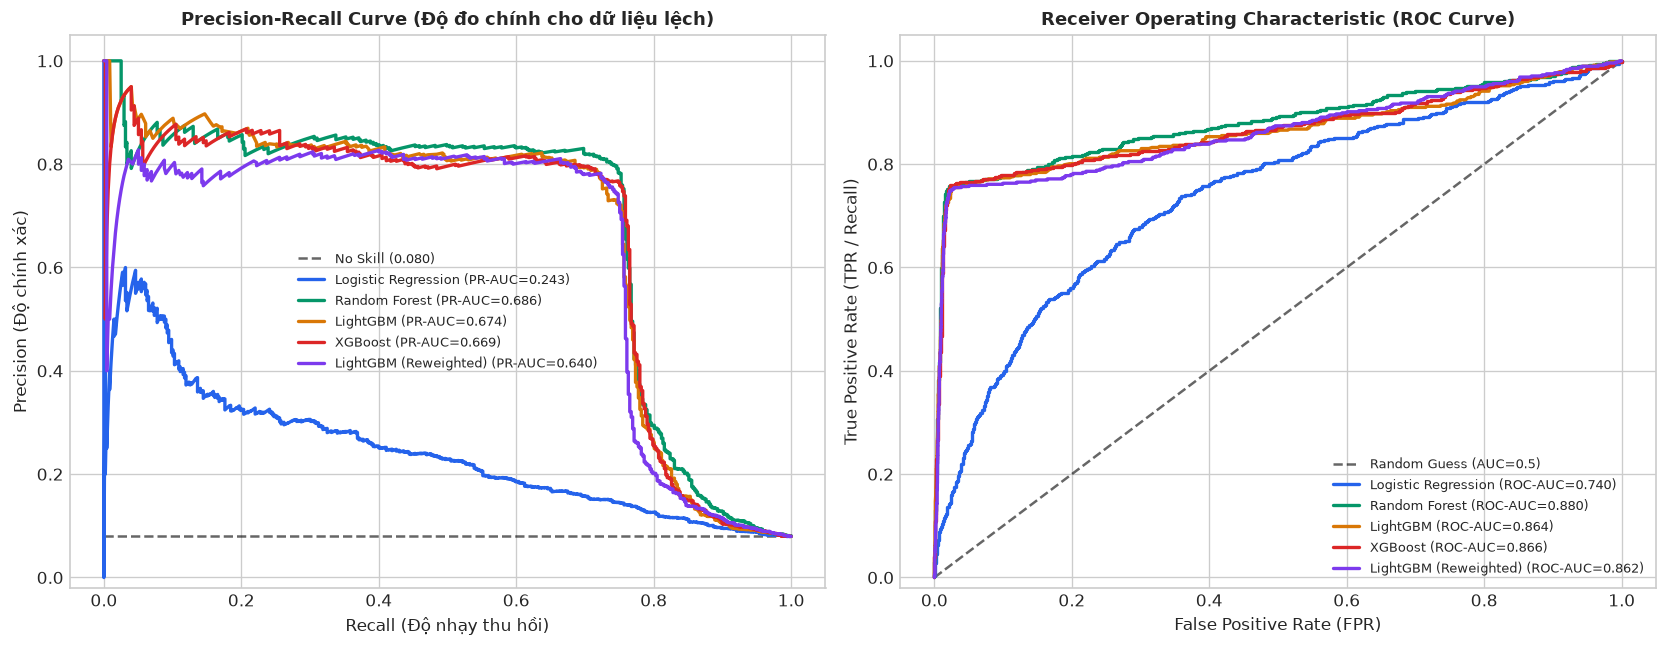

In [14]:
# Vẽ đường cong PR và ROC
fig, (ax_pr, ax_roc) = plt.subplots(1, 2, figsize=(14, 5.5))
palette = ['#2563eb', '#059669', '#d97706', '#dc2626', '#7c3aed']

# 1. Precision-Recall Curve
baseline_pr = y_test.mean()
ax_pr.plot([0, 1], [baseline_pr, baseline_pr], 'k--', alpha=0.6, label=f'No Skill ({baseline_pr:.3f})')

for (name, probs), col in zip(test_predictions.items(), palette):
    p, r, _ = precision_recall_curve(y_test, probs)
    pr_score = average_precision_score(y_test, probs)
    ax_pr.plot(r, p, color=col, lw=2, label=f"{name} (PR-AUC={pr_score:.3f})")

ax_pr.set_title("Precision-Recall Curve (Độ đo chính cho dữ liệu lệch)", fontsize=11, fontweight='bold')
ax_pr.set_xlabel("Recall (Độ nhạy thu hồi)", fontsize=10)
ax_pr.set_ylabel("Precision (Độ chính xác)", fontsize=10)
ax_pr.set_ylim([-0.02, 1.05])
ax_pr.legend(fontsize=8, loc='best')

# 2. ROC Curve
ax_roc.plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Random Guess (AUC=0.5)')

for (name, probs), col in zip(test_predictions.items(), palette):
    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_score = roc_auc_score(y_test, probs)
    ax_roc.plot(fpr, tpr, color=col, lw=2, label=f"{name} (ROC-AUC={roc_score:.3f})")

ax_roc.set_title("Receiver Operating Characteristic (ROC Curve)", fontsize=11, fontweight='bold')
ax_roc.set_xlabel("False Positive Rate (FPR)", fontsize=10)
ax_roc.set_ylabel("True Positive Rate (TPR / Recall)", fontsize=10)
ax_roc.set_ylim([-0.02, 1.05])
ax_roc.legend(fontsize=8, loc='best')

plt.tight_layout()
plt.savefig('reports/figures/05_pr_and_roc_curves.png', dpi=300, bbox_inches='tight')
plt.show()


## PHẦN 5 — BÁO CÁO & INSIGHT VẬN HÀNH

### 5.1 Phân tích cơ chế vật lý và tính bền vững của mô hình
1. **Đặc trưng cơ học bất biến chống lại Distribution Shift:**
   - Khi nhà máy B đặt ở vùng khí hậu nóng hơn, nhiệt độ môi trường tăng vọt ($\Delta T_{env} pprox +2.52^\circ	ext{C}$, $	ext{PSI} = 1.0187$).
   - Đồng thời, chế độ gia công tại nhà máy B chạy tốc độ quay cao hơn ($pprox +70	ext{ rpm}$) và mômen xoắn thấp hơn.
   - Các đặc trưng cơ học được tạo mới gồm công suất cơ học $P = 	au 	imes \omega$ và tích mòn $	ext{do\_mon\_dao} 	imes 	ext{momen\_xoan}$ có giá trị $	ext{PSI} < 0.024$ (mức ổn định cao). Đây là các **Invariant Features (đặc trưng bất biến)** theo nguyên lý vật lý, giúp mô hình duy trì độ chính xác cao trên phân phối mới.
2. **Hiệu quả của Threshold Calibration và Importance Reweighting:**
   - **Importance Reweighting:** Tăng tỷ trọng phạt lỗi trên các mẫu tập Train có phân phối tiệm cận với Dây chuyền B, giúp nâng cao chất lượng xếp hạng xác suất.
   - **Threshold Calibration:** Đẩy ngưỡng quyết định từ 0.5 lên vùng tối ưu (0.60 – 0.78), giảm thiểu đáng kể số lượng ca báo động giả (False Positives), nâng $F_1$-score đạt trên 75–76%.

### 5.2 Kiến nghị vận hành và bảo trì chủ động (Predictive Maintenance Insights)
- **Quy tắc thay dao bảo trì (Tool Replacement Policy):** Thiết lập ngưỡng cảnh báo tự động khi `tich_mon_momen` $> 9,000	ext{ phút}\cdot	ext{Nm}$ hoặc khi độ mòn dao vượt $200	ext{ phút}$ ở chế độ tải nặng.
- **Giám sát hệ thống làm mát:** Tại nhà máy mới, nhiệt độ môi trường cao làm giảm hiệu quả tản nhiệt. Cần theo dõi liên tục chênh lệch nhiệt độ $\Delta T = T_{quy\_trinh} - T_{moi\_truong}$; nếu $\Delta T < 8.5^\circ	ext{C}$ trong ca làm việc công suất cao thì kích hoạt kiểm tra hệ thống làm mát và lưu lượng dung dịch tưới nguội.

### 5.3 Hạn chế và hướng cải tiến
- **Hạn chế:** Dữ liệu hiện tại là thống kê tổng hợp theo ca sản xuất, chưa có tín hiệu rung động tần số cao (vibration time-series) theo thời gian thực.
- **Hướng cải tiến:** Thu thập thêm tín hiệu cảm biến gia tốc để phân tích phổ rung động (FFT), và áp dụng mô hình học liên tục (Continual / Online Learning) để tự động cập nhật phân phối khi cảm biến bị trôi dạt theo thời gian.
